# Helsinki Traffic Forecasting with Traffic and Weather

## Objective and scope
Predict the five-minute average traffic speed ending **15 minutes after the observation time** at five Helsinki-region stations. Compare traffic-only and traffic-plus-weather models against a persistence baseline. This is regression; R² must not be described as classification accuracy.

Real Fintraffic vehicle data and Open-Meteo archived weather forecasts are used. Results apply to later dates at these stations, not automatically to other roads. Weather is modelled, not a roadside observation. All results below are computed from saved real data.

In [1]:
from pathlib import Path
import json, inspect, sys
PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'traffic').exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from traffic.config import DATA, ARTIFACTS, BASE_FEATURES, WEATHER_FEATURES
from traffic.features import supervised, chronological_split
from traffic.model import train_all, predict_rows, load_bundle, make_model
plt.rcParams.update({'figure.figsize': (11,4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 25)


## Data sources and provenance
Traffic: [Digitraffic](https://www.digitraffic.fi/en/road-traffic/lam/), Fintraffic CC BY 4.0. Weather: [Open-Meteo Historical Forecast API](https://open-meteo.com/en/docs/historical-forecast-api), CC BY 4.0; free API is for non-commercial use within its limits.

The manifest records daily source URLs, download timestamps, checksums, missing station-days and quality counts. Fetching can be repeated with `python -m traffic.data --start 2026-09-01 --end 2026-11-13`. Cached daily files avoid unnecessary downloads.

In [2]:
df = pd.read_csv(DATA / 'traffic_weather.csv.gz')
df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)
manifest = json.loads((DATA / 'manifest.json').read_text())
display(pd.Series({k:manifest[k] for k in ['start_date','end_date','raw_rows','valid_raw_rows','aggregated_rows','downloaded_station_days','requested_station_days','weather_missing_fraction']}))
print('Saved table dimensions:', df.shape)
display(df.head())

Saved table dimensions: (206573, 15)


start_date                  2026-09-01
end_date                    2026-11-13
raw_rows                      21557044
valid_raw_rows                21289235
aggregated_rows                 206573
downloaded_station_days            361
requested_station_days             370
weather_missing_fraction      0.001675
dtype: object

,timestamp,direction,speed_kmh,vehicle_count,flow_vph,station_id,temperature_2m,relative_humidity_2m,precipitation,snowfall,wind_speed_10m,weather_time,latitude,longitude,station_name
0,2026-08-31 21:05:00+00:00,1,74.857143,14,168.0,20029,NaN,NaN,NaN,NaN,NaN,NaN,60.229417,24.904984,vt3_Pirkkola_Wavetronix
1,2026-08-31 21:05:00+00:00,2,77.200000,15,180.0,20029,NaN,NaN,NaN,NaN,NaN,NaN,60.229417,24.904984,vt3_Pirkkola_Wavetronix
2,2026-08-31 21:05:00+00:00,1,43.000000,2,24.0,23117,NaN,NaN,NaN,NaN,NaN,NaN,60.202989,24.873178,vt1_Munkkiniemi
3,2026-08-31 21:05:00+00:00,2,45.000000,3,36.0,23117,NaN,NaN,NaN,NaN,NaN,NaN,60.202989,24.873178,vt1_Munkkiniemi
4,2026-08-31 21:05:00+00:00,1,79.696970,33,396.0,23146,NaN,NaN,NaN,NaN,NaN,NaN,60.239547,24.919151,st101_Länsi-Pakila


## Cleaning and temporal alignment
Raw files have 16 semicolon-separated fields. Invalid/faulty speed readings are removed. Ambiguous timestamps during the autumn repeated hour are discarded because their UTC offsets cannot be recovered safely. Vehicle observations are aggregated by station, direction and fixed five-minute window; the timestamp marks the window end. Count is converted to an hourly-equivalent flow by multiplying by 12.

Weather joins use the most recent hourly timestamp at or before the traffic timestamp with a two-hour tolerance. No future-time interpolation is used. A stitched archived forecast is not an issuance-time backtest, so prospective weather validation remains necessary. Missing values are imputed using medians fitted on training data only.

In [3]:
quality = pd.DataFrame({'missing_count':df.isna().sum(), 'missing_percent':100*df.isna().mean()})
display(quality)
display(df.groupby(['station_id','station_name']).agg(rows=('speed_kmh','size'), mean_speed_kmh=('speed_kmh','mean')))
assert not df.duplicated(['timestamp','station_id','direction']).any()
assert df.speed_kmh.between(2,199).all()
if 'weather_time' in df:
    weather_time = pd.to_datetime(df.weather_time, utc=True)
    assert (weather_time.dropna() <= df.loc[weather_time.notna(),'timestamp']).all()
print('Integrity checks passed.')

Integrity checks passed.


,missing_count,missing_percent
timestamp,0,0.000000
direction,0,0.000000
speed_kmh,0,0.000000
vehicle_count,0,0.000000
flow_vph,0,0.000000
station_id,0,0.000000
temperature_2m,346,0.167495
relative_humidity_2m,346,0.167495
precipitation,346,0.167495
snowfall,346,0.167495


,,rows,mean_speed_kmh
station_id,station_name,,
20029,vt3_Pirkkola_Wavetronix,42578,78.008189
23117,vt1_Munkkiniemi,39834,43.724732
23146,st101_Länsi-Pakila,39697,75.969438
23149,st101_Malmi,41889,75.772559
23154,vt4_Viikinmäki,42575,92.712421


## Exploratory analysis

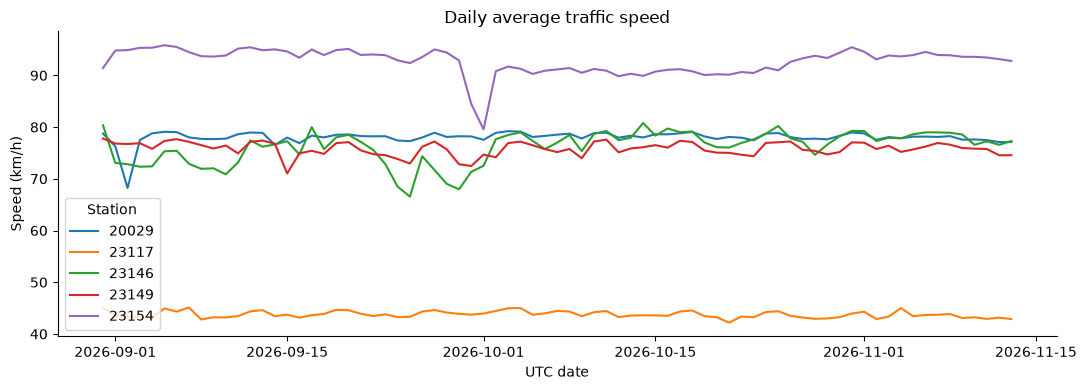

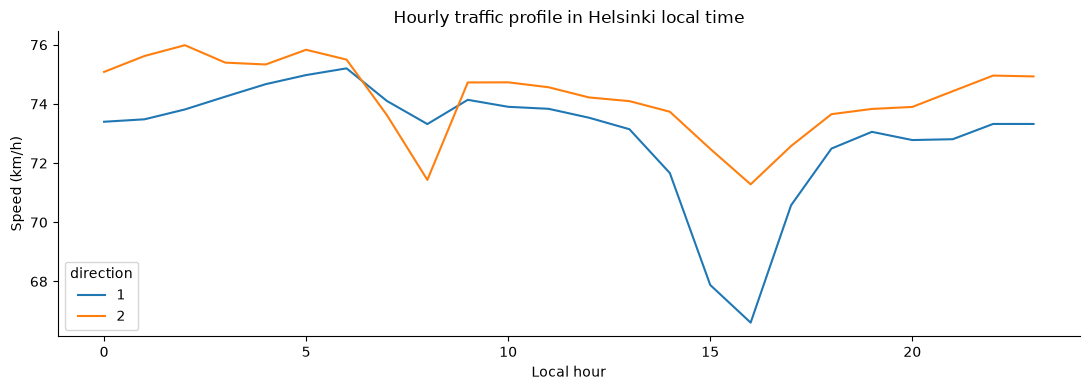

In [4]:
fig, ax = plt.subplots()
for sid, part in df.groupby('station_id'):
    daily=part.set_index('timestamp').speed_kmh.resample('D').mean()
    ax.plot(daily.index,daily,label=str(sid))
ax.set(title='Daily average traffic speed',ylabel='Speed (km/h)',xlabel='UTC date')
ax.legend(title='Station'); plt.tight_layout(); plt.show()

local=df.timestamp.dt.tz_convert('Europe/Helsinki')
profile=df.assign(local_hour=local.dt.hour).groupby(['local_hour','direction']).speed_kmh.mean().unstack()
profile.plot(title='Hourly traffic profile in Helsinki local time',ylabel='Speed (km/h)',xlabel='Local hour')
plt.tight_layout(); plt.show()

Association is not causation; station, season and time of day are confounders.


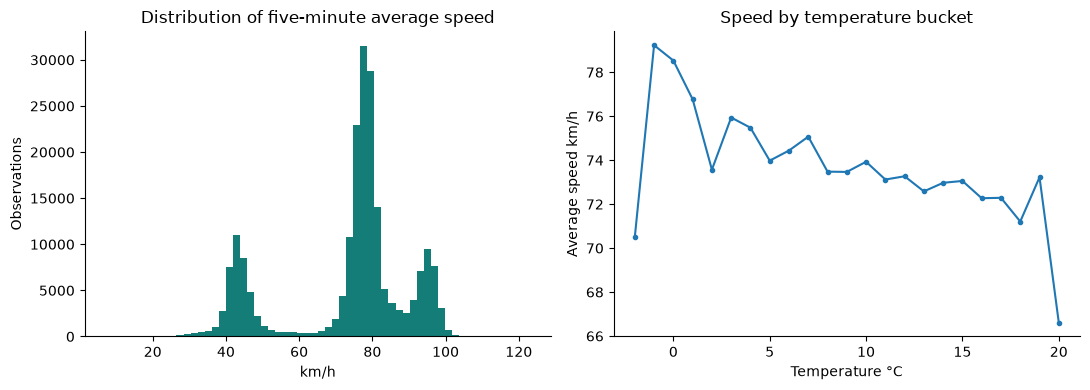

In [5]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].hist(df.speed_kmh,bins=60,color='#147d77')
axes[0].set(title='Distribution of five-minute average speed',xlabel='km/h',ylabel='Observations')
temp=df.groupby(df.temperature_2m.round()).speed_kmh.agg(['mean','size'])
temp=temp[temp['size']>=50]
axes[1].plot(temp.index,temp['mean'],marker='.')
axes[1].set(title='Speed by temperature bucket',xlabel='Temperature °C',ylabel='Average speed km/h')
plt.tight_layout(); plt.show()
print('Association is not causation; station, season and time of day are confounders.')

## Target and features
The target is joined using the **same station and direction at exactly t + 15 minutes**. Gaps are not treated as adjacent observations. Inputs are the latest five-minute speed and flow, station and direction, sine/cosine of local time, weekday, month and weekend indicator. The weather experiment adds temperature, humidity, precipitation, snowfall and wind. No history warm-up is required for this snapshot model.

In [6]:
paired=supervised(df)
train, validation, test=chronological_split(paired)
display(pd.DataFrame([{'partition':name,'rows':len(part),'start':part.timestamp.min(),'end':part.timestamp.max(),'latest_label':part.target_time.max()} for name,part in [('train',train),('validation',validation),('test',test)]]))
assert train.target_time.max() < validation.timestamp.min()
assert validation.target_time.max() < test.timestamp.min()
assert ((paired.target_time-paired.timestamp)==pd.Timedelta('15min')).all()
print('Traffic features:',BASE_FEATURES)
print('Additional weather features:',WEATHER_FEATURES)

Traffic features: ['speed_kmh', 'flow_vph', 'station_id', 'direction', 'hour_sin', 'hour_cos', 'weekday', 'month', 'weekend']
Additional weather features: ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'snowfall', 'wind_speed_10m']


,partition,rows,start,end,latest_label
0,train,144089,2026-08-31 21:05:00+00:00,2026-10-22 14:50:00+00:00,2026-10-22 15:05:00+00:00
1,validation,30553,2026-10-22 15:10:00+00:00,2026-11-02 19:15:00+00:00,2026-11-02 19:30:00+00:00
2,test,31199,2026-11-02 19:35:00+00:00,2026-11-13 21:45:00+00:00,2026-11-13 22:00:00+00:00


## Models and experimental design
Persistence predicts that speed remains unchanged. Random Forest and histogram gradient boosting model nonlinear patterns. Categorical station and direction are one-hot encoded. Numeric missing values use training medians. A fixed seed supports reproducibility.

The earliest 70% of observation timestamps form training, the next 15% validation, and the final 15% test. Labels crossing partition boundaries are purged. Choose each feature-set winner by validation MAE, refit it on training plus validation, and then evaluate on test. The automatic dashboard model is also selected on validation. Test scores are never used to tune hyperparameters.

In [7]:
# Inspect the actual shared pipeline used in both the notebook and application.
print(inspect.getsource(make_model))
# Set True to rerun every candidate. False uses the already measured artifacts.
RETRAIN = False
if RETRAIN or not (ARTIFACTS/'summary.json').exists():
    summary=train_all()
else:
    summary=json.loads((ARTIFACTS/'summary.json').read_text())
    print('Loaded completed experiment from',summary['created_at'])
validation_metrics=pd.read_csv(ARTIFACTS/'validation_metrics.csv')
test_metrics=pd.read_csv(ARTIFACTS/'test_metrics.csv')
display(validation_metrics)
display(test_metrics)

def make_model(algorithm, features):
    categorical = ['station_id', 'direction']
    numeric = [c for c in features if c not in categorical]
    pre = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), numeric),
        ('station', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical),
    ])
    if algorithm == 'Random forest':
        estimator = RandomForestRegressor(n_estimators=100, min_samples_leaf=8, max_depth=18, max_features=.9, n_jobs=-1, random_state=42)
    else:
        estimator = HistGradientBoostingRegressor(max_iter=150, learning_rate=.07, max_leaf_nodes=25, l2_regularization=2, early_stopping=False, random_state=42)
    return Pipeline([('prepare', pre), ('regressor', estimator)])

Loaded completed experiment from 2026-11-16T15:31:38.159874+00:00


,mode,algorithm,MAE_kmh,RMSE_kmh,R2
0,traffic,Persistence,2.249565,3.634044,0.954854
1,traffic,Random forest,2.043831,3.224587,0.964454
2,traffic,Gradient boosting,1.928186,2.999808,0.969237
3,weather,Persistence,2.249565,3.634044,0.954854
4,weather,Random forest,2.049765,3.256433,0.963749
5,weather,Gradient boosting,1.929204,3.027497,0.968667


,mode,algorithm,MAE_kmh,RMSE_kmh,R2
0,traffic,Gradient boosting,1.864313,2.918839,0.969091
1,weather,Gradient boosting,1.884443,2.960162,0.968210
2,baseline,Persistence,2.342668,3.748908,0.949012


## Test results and weather comparison
MAE is the average absolute error in km/h; RMSE gives greater weight to large errors; R² compares squared error with a constant mean predictor. Lower MAE/RMSE are better. Weather is retained as an explicit comparison even if it does not improve forecasting.

Validation-selected default: traffic
Test MAE: 1.864 km/h; persistence: 2.343 km/h
Test MAE reduction relative to persistence: 20.4%
Weather improves test MAE in this run: False


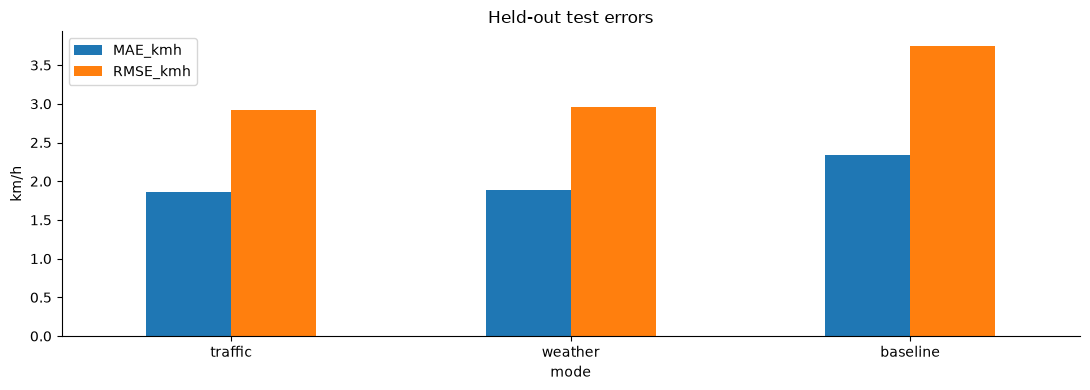

In [8]:
baseline=test_metrics.loc[test_metrics['mode']=='baseline','MAE_kmh'].iloc[0]
best_mode=summary['default_mode']
best=test_metrics.loc[test_metrics['mode']==best_mode,'MAE_kmh'].iloc[0]
print(f'Validation-selected default: {best_mode}')
print(f'Test MAE: {best:.3f} km/h; persistence: {baseline:.3f} km/h')
print(f'Test MAE reduction relative to persistence: {100*(baseline-best)/baseline:.1f}%')
weather_mae=test_metrics.loc[test_metrics['mode']=='weather','MAE_kmh'].iloc[0]
traffic_mae=test_metrics.loc[test_metrics['mode']=='traffic','MAE_kmh'].iloc[0]
print('Weather improves test MAE in this run:',weather_mae < traffic_mae)
test_metrics.set_index('mode')[['MAE_kmh','RMSE_kmh']].plot.bar(rot=0,title='Held-out test errors')
plt.ylabel('km/h');plt.tight_layout();plt.show()

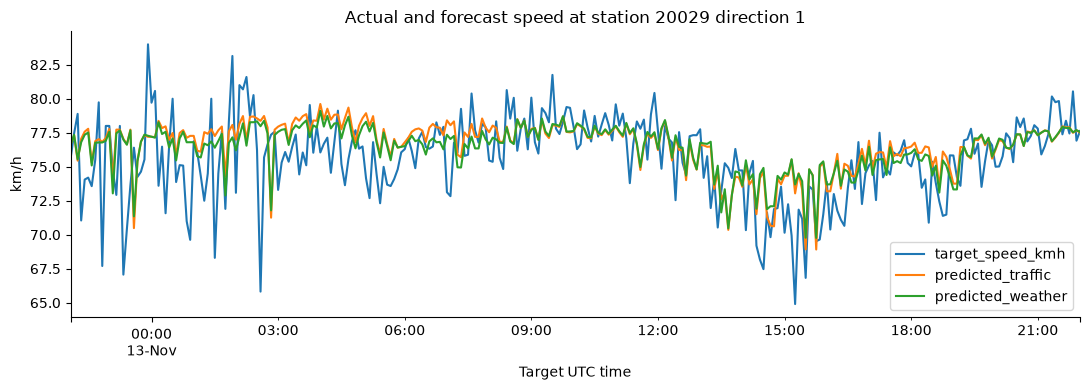

rows  traffic_MAE  weather_MAE
station_id direction                                  
20029      1          3187.0     1.828928     1.827884
           2          3191.0     1.560005     1.574505
23117      1          2835.0     1.801272     1.816962
           2          2832.0     2.013894     2.019120
23146      1          3195.0     1.511623     1.532723
           2          3195.0     1.486619     1.527241
23149      1          3195.0     2.199570     2.276752
           2          3195.0     1.728697     1.729794
23154      1          3189.0     2.080989     2.074540
           2          3185.0     2.443169     2.474277

In [9]:
pred=pd.read_csv(ARTIFACTS/'test_predictions.csv.gz')
pred['target_time']=pd.to_datetime(pred.target_time,utc=True)
example=pred[(pred.station_id==20029)&(pred.direction==1)].tail(288)
example.set_index('target_time')[['target_speed_kmh','predicted_traffic','predicted_weather']].plot(title='Actual and forecast speed at station 20029 direction 1',ylabel='km/h',xlabel='Target UTC time')
plt.tight_layout();plt.show()
display(pred.groupby(['station_id','direction']).apply(lambda g:pd.Series({'rows':len(g),'traffic_MAE':np.abs(g.target_speed_kmh-g.predicted_traffic).mean(),'weather_MAE':np.abs(g.target_speed_kmh-g.predicted_weather).mean()})))

Computed on validation with a model fitted only on training.


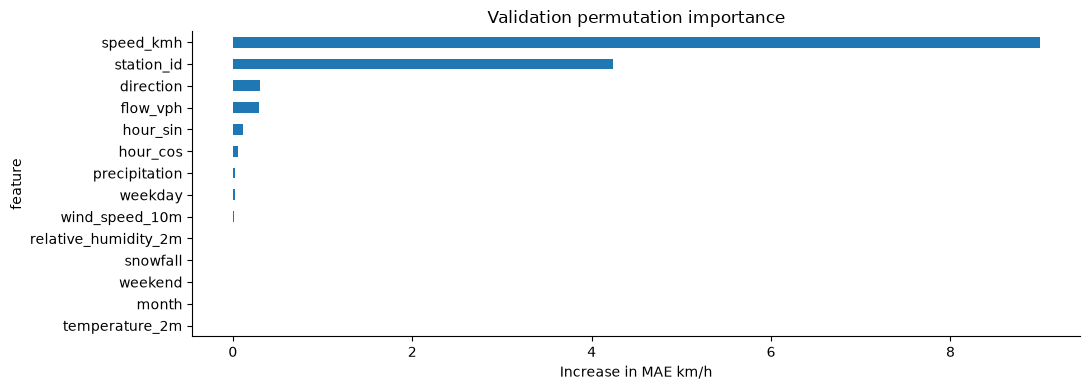

In [10]:
importance_path=ARTIFACTS/'feature_importance.csv'
if importance_path.exists():
    imp=pd.read_csv(importance_path)
    imp.sort_values('mae_increase').plot.barh(x='feature',y='mae_increase',legend=False,title='Validation permutation importance',xlabel='Increase in MAE km/h')
    plt.tight_layout();plt.show()
    print('Computed on validation with a model fitted only on training.')

## Saved model and dashboard inference
The application loads the trusted saved pipeline and applies the same feature function. Missing live weather triggers the separately evaluated traffic-only model. Live windows are rolling provider estimates, whereas historical windows are fixed raw aggregates. Live units and timestamp freshness are checked; stale predictions are refused.

The congestion display uses speed divided by a training-only reference speed: below 0.70 is Heavy, below 0.90 is Moderate, otherwise Low. These are project definitions, not official congestion labels.

In [11]:
bundle=load_bundle()
display(predict_rows(df.tail(5),bundle,mode='auto'))
print('Launch: python -m streamlit run app.py')

Launch: python -m streamlit run app.py


,timestamp,station_id,direction,speed_kmh,flow_vph,prediction_at,predicted_speed_kmh,model_mode,algorithm,weather_fallback,reference_speed_kmh,congestion
206568,2026-11-13 22:00:00+00:00,23146,2,81.000000,576.0,2026-11-13 22:15:00+00:00,81.058726,traffic,Gradient boosting,False,83.464286,Low
206569,2026-11-13 22:00:00+00:00,23149,1,78.848485,396.0,2026-11-13 22:15:00+00:00,77.589075,traffic,Gradient boosting,False,81.333333,Low
206570,2026-11-13 22:00:00+00:00,23149,2,75.486486,444.0,2026-11-13 22:15:00+00:00,76.828672,traffic,Gradient boosting,False,80.963823,Low
206571,2026-11-13 22:00:00+00:00,23154,1,93.324324,444.0,2026-11-13 22:15:00+00:00,94.256159,traffic,Gradient boosting,False,99.582242,Low
206572,2026-11-13 22:00:00+00:00,23154,2,96.941176,408.0,2026-11-13 22:15:00+00:00,94.167268,traffic,Gradient boosting,False,97.000000,Low


## Conclusions and limitations
The saved tables above contain the actual measured results. No classification accuracy or prediction confidence is inferred from R². This experiment compares traffic and weather features using chronological holdout data. It does not establish that weather causes congestion or that performance will transfer to other roads.

The deployment should monitor future errors, provider outages, changing road limits and seasonal shifts. Extend collection across a full year and conduct issuance-time weather evaluation before making stronger operational claims. The historical weather comparison is retrospective. Repeat training after expanding the archive; preserve a new final test period.

## Reproduction and sources
1. Install `requirements.txt` in Python 3.12.
2. Run the historical downloader, then `python -m traffic.model`.
3. Execute this notebook with `RETRAIN=True` for a fresh experiment.
4. Run tests with `python -m unittest discover -s tests -v`.
5. Start Streamlit. Historical replay works from included data; live requests require internet.

Traffic source: https://www.digitraffic.fi/en/road-traffic/  
Traffic format: https://www.digitraffic.fi/en/road-traffic/lam/  
Weather source: https://open-meteo.com/en/docs/historical-forecast-api  
Weather use terms: https://open-meteo.com/en/terms

Attribution: Fintraffic / digitraffic.fi and Open-Meteo, CC BY 4.0. Data were filtered, aggregated and joined.